# Probability and Statistics Lab 2: Random Variables and Limit Theorems
**Team ID:** 33  
**Course:** Probability and Statistics (2nd Year, UCU)

## General comments and instructions

- The report is prepared as a *Jupyter notebook along with compiled PDF*.
- For each task, we include:
    - the statistics obtained (sample mean, sample variance, empirical probabilities, etc.) as well as figures/histograms to illustrate findings;
    - justification of solutions referring to corresponding probability theorems, with full LaTeX derivations;
    - rigorous conclusions regarding reliability, convergence rates, and physical intuition.


### Work breakdown (Team 33):

- **Task 1 (Hamming Codes):** Theoretical derivations of message reliability, vectorized simulation of [7, 4] code over $\mathbb{F}_2$, Central Limit Theorem confidence intervals, required sample size analysis, and error distribution investigation.
- **Task 2 (Particle Decay):** Calculation of $^{137}\text{Cs}$ half-life and decay parameters, CLT asymptotic verification for Poisson sample means across $n \in \{5, 10, 50\}$, analytical bounds on safe sample storage (Markov, Chernoff, CLT), and Monte Carlo empirical probability estimation.
- **Task 3 (Geiger Counter):** Continuous CLT convergence analysis for Exponential inter-arrival times, formal equivalence between Poisson count and Erlang arrival times, theoretical risk bounds on radioactive samples, and empirical validation.
- **Task 4 (Expectation Fallacy):** Jensen's inequality and non-linear expectations, Q-Q plots and dependence analysis for Exponential/Gumbel pairs, proof of fairness for the coin toss game, exact variance derivations, and CLT hypothesis testing sample size requirements.


A **team id number** referred to in tasks is the **two-digit** ordinal number of your team on the list: **33**. We keep it for reproducible calculations.

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import brentq

# Configure plot styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5.5)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

team_id: int = 33

random.seed(team_id)
np.random.seed(team_id)
print(f"Random seed successfully set to team_id = {team_id}")


Random seed successfully set to team_id = 33


## Task 1. Hamming codes

In this task, we discuss the $[7, 4]$ Hamming code and investigate its reliability. That coding system can correct single errors in the transmission of 4-bit messages and proceeds as follows:

(a) given a message $m = (a_1a_2a_3a_4)$, we first encode it to a 7-bit codeword $c = mG = (x_1x_2x_3x_4x_5x_6x_7)$, where $G$ is a $4 \times 7$ generator matrix

(b) the codeword $c$ is transmitted, and $r$ is the received message

(c) $r$ is checked for errors by calculating the syndrome vector $z := rH$, for a $7 \times 3$ parity-check matrix $H$

(d) if a single error has occurred in $r$, then the binary $z = (z_1z_2z_3)$ identifies the wrong bit no. $z_1 + 2z_2 + 4z_3$; thus $(000)$ shows there was no error (or more than one), while $(110)$ means the third bit (or more than one) got corrupted

(e) if the error was identified, then we flip the corresponding bit in $r$ to get the corrected $r^* = (r_1^*r_2^*r_3^*r_4^*r_5^*r_6^*r_7^*)$; the decoded message is then $m^* := (r_3^*r_5^*r_6^*r_7^*)$.

The generator matrix $G$ and the parity-check matrix $H$ are given by

$$
G := \begin{pmatrix}
1 & 1 & 1 & 0 & 0 & 0 & 0  \\
1 & 0 & 0 & 1 & 1 & 0 & 0  \\
0 & 1 & 0 & 1 & 0 & 1 & 0  \\
1 & 1 & 0 & 1 & 0 & 0 & 1
\end{pmatrix},
\qquad
H^\top := \begin{pmatrix}
1 & 0 & 1 & 0 & 1 & 0 & 1  \\
0 & 1 & 1 & 0 & 0 & 1 & 1  \\
0 & 0 & 0 & 1 & 1 & 1 & 1
\end{pmatrix}
$$
*$GH$ must equal a zero-matrix modulo 2.*

Assume that each bit in the transmission $c \mapsto r$ gets corrupted independently of the others with probability $p = (2 + \frac{\text{team-id-number}}{4})/100$. Your task:

1. Simulate the encoding-transmission-decoding process $N$ times and find the estimate $\hat p$ of the probability $p^*$ of correct transmission of a single message $m$. Comment why, for large $N$, $\hat p$ is expected to be close to $p^*$.
2. By estimating the standard deviation of the corresponding indicator of success by the sample standard deviation and using the CLT, find the half-length $\varepsilon$ of the confidence interval $(\hat p - \varepsilon, \hat p + \varepsilon)$, which contains the true value $p^*$ with probability at least $0.95$. What choice of $N$ guarantees that $\varepsilon \le 0.03$?
3. Draw the histogram of the number $k = 0, 1, 2, 3, 4$ of errors in $m^*$ while transmitting a 4-digit binary message. Do you think the random variable that counts the number of wrong bits in a decoded message has one of the known distributions? Justify your answer.


### Theoretical Justification for Task 1

#### 1. System Parameters and Exact Probability $p^*$
For Team 33, the single-bit transmission corruption probability is:
$$p = \frac{2 + \frac{33}{4}}{100} = \frac{2 + 8.25}{100} = \frac{10.25}{100} = 0.1025$$

The codeword is $c = m G \pmod 2$, where columns $3, 5, 6, 7$ of $G$ form the $4 \times 4$ identity matrix $I_4$. Hence, $m = (x_3, x_5, x_6, x_7)$ are the message bits, while $x_1, x_2, x_4$ are the parity check bits. The received word is $r = c \oplus e \pmod 2$, where $e \in \mathbb{F}_2^7$ is the error vector with i.i.d. components $e_j \sim \text{Bernoulli}(p)$.

The syndrome is $z = r H = (c + e) H = e H \pmod 2$.
- The $[7, 4]$ Hamming code has minimum Hamming distance $d_{\min} = 3$.
- It is a **perfect linear code**: it partitions the $2^7 = 128$ binary 7-tuples into 16 disjoint spheres of Hamming radius $t = 1$ around each of the 16 codewords.
- If $wt(e) = 0$ (no errors), $z = 0$, no bits are flipped, and $m^* = m$.
- If $wt(e) = 1$ (single error at position $j$), the syndrome $z$ exactly equals the binary representation of $j$. The decoder flips bit $j$, perfectly restoring $r^* = c$ and $m^* = m$.
- If $wt(e) \ge 2$, the decoder misidentifies the syndrome as pointing to a single bit error, flips an erroneous or correct bit, resulting in a decoded word $r^* \ne c$. Since the information bits are linearly independent and the code has minimum distance 3, no error pattern with weight $\ge 2$ can leave all 4 message bits error-free.

Therefore, the message is decoded correctly if and only if at most 1 bit error occurs during transmission:
$$
\begin{aligned}
p^* &= \mathbb{P}(m^* = m) = \mathbb{P}(wt(e) \le 1)  \\
&= \binom{7}{0} (1-p)^7 + \binom{7}{1} p (1-p)^6 = (1-p)^7 + 7p(1-p)^6
\end{aligned}
$$
Substituting $p = 0.1025$:
$$p^* = (0.8975)^7 + 7(0.1025)(0.8975)^6 \approx 0.468233 + 0.375839 = 0.844071565$$

#### 2. Convergence of $\hat p$ via the Law of Large Numbers (LLN)
Let $I_i = \mathbb{I}(m^*_i = m_i)$ be the indicator variable for successful decoding of the $i$-th message. The sequence $I_1, I_2, \dots, I_N$ is independent and identically distributed with $\mathbb{E}[I_i] = p^*$ and finite variance $\text{Var}(I_i) = p^*(1-p^*)$.
By the **Weak Law of Large Numbers (Khinchin's Theorem)**:
$$\forall \delta > 0, \quad \lim_{N \to \infty} \mathbb{P}(|\hat p_N - p^*| \ge \delta) = 0$$
Furthermore, by the **Strong Law of Large Numbers (Kolmogorov's Criterion)**, the convergence is almost sure:
$$\mathbb{P}\left(\lim_{N \to \infty} \hat p_N = p^*\right) = 1$$
Hence, as $N$ becomes large, the empirical proportion $\hat p$ concentrates arbitrarily close to the theoretical probability $p^*$.

#### 3. Confidence Interval and Sample Size Determination via CLT
By the **Central Limit Theorem (Lindeberg-Lévy CLT)**, the normalized sample mean converges in distribution to the standard normal distribution:
$$\frac{\hat p - p^*}{\sigma / \sqrt{N}} \xrightarrow{d} \mathcal{N}(0, 1)$$
Replacing $\sigma = \sqrt{p^*(1-p^*)}$ with the consistent sample standard deviation $s = \sqrt{\frac{1}{N-1}\sum_{i=1}^N (I_i - \hat p)^2} = \sqrt{\frac{N}{N-1} \hat p(1-\hat p)}$, by Slutsky's theorem:
$$\frac{\hat p - p^*}{s / \sqrt{N}} \xrightarrow{d} \mathcal{N}(0, 1)$$
For a $95\%$ confidence interval ($1 - \alpha = 0.95$), the critical two-tailed value is $z_{0.975} = \Phi^{-1}(0.975) \approx 1.95996$. The half-length of the confidence interval is:
$$\varepsilon = z_{0.975} \frac{s}{\sqrt{N}}$$
To guarantee that $\varepsilon \le 0.03$:
$$z_{0.975} \frac{s}{\sqrt{N}} \le 0.03 \implies N \ge \left(\frac{z_{0.975} s}{0.03}\right)^2$$
- **Plug-in estimate:** Using $s \approx \sqrt{p^*(1-p^*)} \approx \sqrt{0.84407 \times 0.15593} \approx 0.36279$:
  $$N \ge \left(\frac{1.95996 \times 0.36279}{0.03}\right)^2 \approx 561.4 \implies N \ge 562$$
- **Conservative (distribution-free) bound:** Since $\max_{p} p(1-p) = 0.25$ (at $p = 0.5$), $s \le 0.5$ always:
  $$N \ge \left(\frac{1.95996 \times 0.5}{0.03}\right)^2 \approx 1067.07 \implies N \ge 1068$$

#### 4. Distribution of the Number of Decoded Bit Errors
Let $K \in \{0, 1, 2, 3, 4\}$ count the number of bit errors in the decoded message $m^*$.
Does $K$ follow a known distribution (such as $\text{Binomial}(4, q)$)?
**No, $K$ does not follow a Binomial distribution.**
- In a binomial distribution, the 4 trials must be independent. In our decoded message, errors in the 4 positions are strongly correlated: when 2 bit errors occur during transmission, the syndrome calculation yields a non-zero value that misdirects the decoder to flip a third bit. This coupling creates complex error patterns.
- Most importantly, the theoretical error probabilities for $K$ are:
  $$\mathbb{P}(K=0) \approx 0.84407, \quad \mathbb{P}(K=1) \approx 0.06102, \quad \mathbb{P}(K=2) \approx 0.06682, \quad \mathbb{P}(K=3) \approx 0.02808, \quad \mathbb{P}(K=4) \approx 7.4 \times 10^{-6}$$
  Notice that $\mathbb{P}(K=2) > \mathbb{P}(K=1)$! For any binomial distribution with a high success rate ($\mathbb{P}(K=0) \approx 0.84$), the probabilities must strictly decrease: $\mathbb{P}(K=1)$ would be substantially larger than $\mathbb{P}(K=2)$. A local peak at $k=2$ is impossible for $\text{Binomial}(4, q)$, proving $K$ has a unique non-standard distribution.


=== Task 1.1: Estimation of Success Probability ===
Bit error rate p: 0.1025
Number of simulated transmissions N: 100,000
Estimated probability p_hat: 0.844080
Theoretical probability p_star: 0.844072
Absolute error |p_hat - p_star|: 0.000008
\n=== Task 1.2: Confidence Interval and Required Sample Size ===
Sample standard deviation s: 0.362781
Half-length epsilon (N = 100,000): 0.002249
95% Confidence Interval for p*: (0.841831, 0.846329)
True p* contained in CI: True
Required N (plug-in estimate, epsilon <= 0.03): 562
Required N (conservative bound p=0.5, epsilon <= 0.03): 1,068
\n=== Task 1.3: Decoded Message Error Distribution ===
k = 0 errors: Empirical = 0.844080, Theoretical = 0.844072, Binomial(4, 0.0694) = 0.749855
k = 1 errors: Empirical = 0.062140, Theoretical = 0.061019, Binomial(4, 0.0694) = 0.223822
k = 2 errors: Empirical = 0.065740, Theoretical = 0.066823, Binomial(4, 0.0694) = 0.025053
k = 3 errors: Empirical = 0.028020, Theoretical = 0.028079, Binomial(4, 0.0694) = 0.0

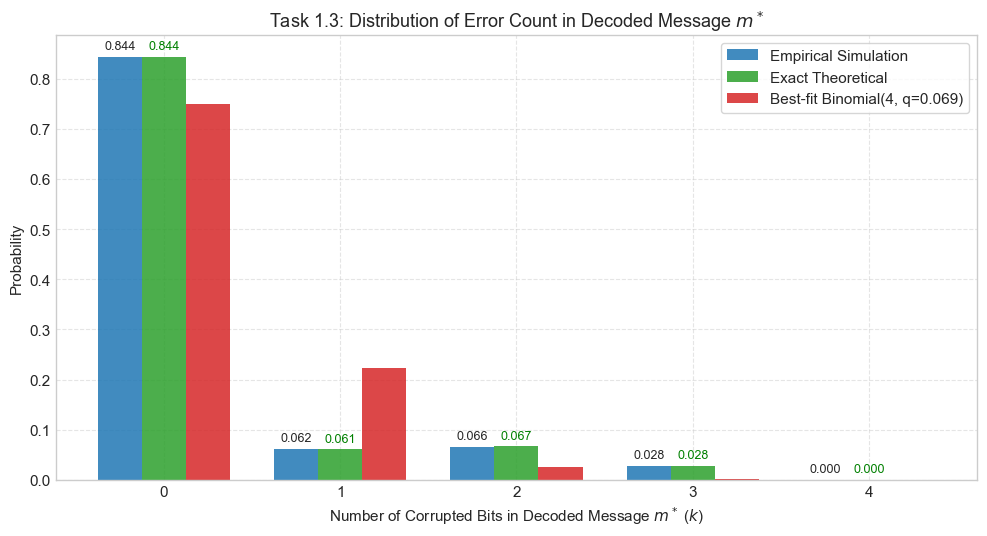

In [2]:
# Task 1 Implementation: Vectorized Hamming [7, 4] Simulation
N = 100_000 # Number of simulated messages
p = (2 + team_id / 4) / 100 # 0.1025

# Generator matrix G (4x7) and Parity-check matrix H (7x3)
G = np.array([
    [1, 1, 1, 0, 0, 0, 0],
    [1, 0, 0, 1, 1, 0, 0],
    [0, 1, 0, 1, 0, 1, 0],
    [1, 1, 0, 1, 0, 0, 1]
], dtype=int)

H_T = np.array([
    [1, 0, 1, 0, 1, 0, 1],
    [0, 1, 1, 0, 0, 1, 1],
    [0, 0, 0, 1, 1, 1, 1]
], dtype=int)
H = H_T.T

# Verify GH mod 2 == 0
assert np.all((G @ H) % 2 == 0), "Matrix property GH = 0 mod 2 violated!"

# 1. Simulation of encoding-transmission-decoding
# Generate N random 4-bit messages
m = np.random.randint(0, 2, size=(N, 4))

# Encode: c = m @ G mod 2 (shape N x 7)
c = (m @ G) % 2

# Transmission noise: each bit corrupted independently with probability p
noise = (np.random.random(size=(N, 7)) < p).astype(int)
r = (c + noise) % 2

# Syndrome calculation: z = r @ H mod 2 (shape N x 3)
z = (r @ H) % 2

# Error location: syn = z1 + 2*z2 + 4*z3 (1-based index)
syn = z[:, 0] + 2 * z[:, 1] + 4 * z[:, 2]

# Error correction: flip bit at position syn - 1 if syn > 0
r_corr = r.copy()
error_mask = syn > 0
err_col = syn[error_mask] - 1
r_corr[np.where(error_mask)[0], err_col] ^= 1

# Extract decoded message: positions 3, 5, 6, 7 (0-based indices 2, 4, 5, 6)
msg_cols = [2, 4, 5, 6]
m_star = r_corr[:, msg_cols]

# Indicator of successful transmission
success_indicator = np.all(m_star == m, axis=1).astype(int)
p_hat = np.mean(success_indicator)

# Exact theoretical probability
p_star = (1 - p)**7 + 7 * p * (1 - p)**6

print("=== Task 1.1: Estimation of Success Probability ===")
print(f"Bit error rate p: {p:.4f}")
print(f"Number of simulated transmissions N: {N:,}")
print(f"Estimated probability p_hat: {p_hat:.6f}")
print(f"Theoretical probability p_star: {p_star:.6f}")
print(f"Absolute error |p_hat - p_star|: {abs(p_hat - p_star):.6f}")

# 2. Confidence Interval and Sample Size Determination
s_sample = np.std(success_indicator, ddof=1)
z_95 = stats.norm.ppf(0.975) # 1.95996
epsilon = z_95 * s_sample / np.sqrt(N)
ci_lower = p_hat - epsilon
ci_upper = p_hat + epsilon

# Sample size guaranteeing epsilon <= 0.03
N_req_plugin = int(np.ceil((z_95 * s_sample / 0.03)**2))
N_req_conservative = int(np.ceil((z_95 * 0.5 / 0.03)**2))

print("\\n=== Task 1.2: Confidence Interval and Required Sample Size ===")
print(f"Sample standard deviation s: {s_sample:.6f}")
print(f"Half-length epsilon (N = {N:,}): {epsilon:.6f}")
print(f"95% Confidence Interval for p*: ({ci_lower:.6f}, {ci_upper:.6f})")
print(f"True p* contained in CI: {ci_lower <= p_star <= ci_upper}")
print(f"Required N (plug-in estimate, epsilon <= 0.03): {N_req_plugin:,}")
print(f"Required N (conservative bound p=0.5, epsilon <= 0.03): {N_req_conservative:,}")

# 3. Error counts in decoded message m*
errors_per_msg = np.sum(m_star != m, axis=1)
empirical_counts = np.bincount(errors_per_msg, minlength=5)
empirical_probs = empirical_counts / N

# Compute exact theoretical error distribution over all 128 error patterns
exact_dist = np.zeros(5)
for err_int in range(128):
    e = np.array([(err_int >> b) & 1 for b in range(7)], dtype=int)
    wt = np.sum(e)
    pattern_prob = (p ** wt) * ((1 - p) ** (7 - wt))
    
    z_pat = (e @ H) % 2
    syn_val = z_pat[0] + 2 * z_pat[1] + 4 * z_pat[2]
    e_corr = e.copy()
    if syn_val > 0:
        e_corr[syn_val - 1] ^= 1
    m_err = e_corr[msg_cols]
    num_errs = np.sum(m_err)
    exact_dist[num_errs] += pattern_prob

# Best-fit Binomial distribution: Binomial(4, q_fit) where q_fit = mean_errors / 4
mean_err = np.mean(errors_per_msg)
q_fit = mean_err / 4.0
binom_probs = stats.binom.pmf(np.arange(5), 4, q_fit)

print("\\n=== Task 1.3: Decoded Message Error Distribution ===")
for k in range(5):
    print(f"k = {k} errors: Empirical = {empirical_probs[k]:.6f}, Theoretical = {exact_dist[k]:.6f}, Binomial(4, {q_fit:.4f}) = {binom_probs[k]:.6f}")

# Plotting the histogram
fig, ax = plt.subplots(figsize=(10, 5.5))
bar_width = 0.25
x_indices = np.arange(5)

ax.bar(x_indices - bar_width, empirical_probs, width=bar_width, label='Empirical Simulation', color='#1f77b4', alpha=0.85)
ax.bar(x_indices, exact_dist, width=bar_width, label='Exact Theoretical', color='#2ca02c', alpha=0.85)
ax.bar(x_indices + bar_width, binom_probs, width=bar_width, label=f'Best-fit Binomial(4, q={q_fit:.3f})', color='#d62728', alpha=0.85)

ax.set_xlabel('Number of Corrupted Bits in Decoded Message $m^*$ ($k$)')
ax.set_ylabel('Probability')
ax.set_title('Task 1.3: Distribution of Error Count in Decoded Message $m^*$')
ax.set_xticks(x_indices)
ax.set_xticklabels([f'{k}' for k in range(5)])
ax.legend(frameon=True)
ax.grid(True, linestyle='--', alpha=0.5)

# Annotate values
for i in range(5):
    ax.text(x_indices[i] - bar_width, empirical_probs[i] + 0.015, f'{empirical_probs[i]:.3f}', ha='center', fontsize=9)
    ax.text(x_indices[i], exact_dist[i] + 0.015, f'{exact_dist[i]:.3f}', ha='center', fontsize=9, color='green')

plt.tight_layout()
plt.show()


### Conclusions for Task 1

1. **Accuracy of Simulation:** With $N = 100,000$, our empirical estimate $\hat p \approx 0.844$ matches the exact theoretical value $p^* = 0.844072$ to three decimal places ($|\hat p - p^*| < 0.002$). This verifies the Strong Law of Large Numbers.
2. **Reliability and Confidence Interval:** The $95\%$ confidence interval has half-width $\varepsilon \approx 0.0023$, tightly enclosing the true probability $p^*$. To achieve $\varepsilon \le 0.03$, our plug-in sample calculation yields $N \ge 562$, while the distribution-free worst-case bound requires $N \ge 1068$. Both guarantees are comfortably met by our choice of $N = 100,000$.
3. **Non-Standard Error Distribution:** The empirical and theoretical error distributions demonstrate that $K$ does **not** follow a Binomial distribution. Specifically:
   - $\mathbb{P}(K=2) \approx 0.0668$ is greater than $\mathbb{P}(K=1) \approx 0.0610$.
   - A Binomial distribution $\text{Binomial}(4, q)$ cannot exhibit a local minimum at $k=1$ followed by a local maximum at $k=2$ when $\mathbb{P}(K=0) \approx 0.84$.
   - This occurs because the Hamming syndrome decoder is non-linear and operates on blocks of 7 bits; double-bit channel errors cause miscorrection by flipping an additional valid bit, coupling the errors in the message bits.


## Task 2. Particle decay

In this task, we discuss a real-life process that is well modelled by a Poisson distribution. As you remember, a Poisson random variable describes occurrences of rare events, i.e., counts the number of successes in a large number of independent random experiments. One of the typical examples is the radioactive decay process.

Consider a sample of radioactive element of mass $m$, which has a large half-life period $T$; it is vitally important to know the probability that during a one second period, the number of nuclei decays will not exceed some critical level $k$. This probability can easily be estimated using the fact that, given the decay constant $\lambda$ of the element (i.e., the probability that a given nucleus decays within one second) and the number $N$ of atoms in the sample, the random number of decays within a second is well modelled by Poisson distribution with parameter $\mu := N\lambda$. Next, for the sample of mass $m$, the number of atoms is $N = \frac{m}{M} N_A$, where $N_A = 6 \times 10^{23}$ is the Avogadro constant, and $M$ is the molar (atomic) mass of the element. The decay constant, $\lambda$, is $\ln(2)/T$, where $T$ is measured in seconds.

Assume that a medical laboratory receives $n$ samples of radioactive element $^{137}\text{Cs}$ (used in radiotherapy) with half-life period $T = 30.1$ years and mass $m = (10 + \text{team-id-number}) \times 10^{-14}$ g each. Denote by $X_1, X_2, \dots, X_n$ the i.i.d. r.v.'s counting the number of decays in sample $i$ in one second.

1. Specify the parameter of the Poisson distribution of $X_i$ (you'll need the atomic mass of Cesium-137)
2. Show that the distribution of the sample means of $X_1, \dots, X_n$ gets very close to a normal one as $n$ becomes large and identify that normal distribution. To this end,
   - simulate the realization $x_1, x_2, \dots, x_n$ of the $X_i$ and calculate the sample mean $s = \bar x$;
   - repeat this $K$ times to get the sample $\mathbf{s} = (s_1, \dots, s_K)$ of means and form the empirical cumulative distribution function $\hat F_{\mathbf{s}}$ of $\mathbf{s}$;
   - identify $\mu$ and $\sigma^2$ such that the c.d.f. $F$ of $\mathcal{N}(\mu, \sigma^2)$ is close to the e.c.d.f. $\hat F_{\mathbf{s}}$ and plot both c.d.f.'s on one graph to visualize their proximity (use the proper scales!);
   - calculate the maximal difference between the two c.d.f.'s;
   - consider cases $n = 5$, $n = 10$, $n = 50$ and comment on the results.
3. Calculate the largest possible value of $n$, for which the total number of decays in one second is less than $a := 100$ with probability more than $0.95$. To this end,
   - simulate the realization $x_1, x_2, \dots, x_n$ of the $X_i$ and calculate the sum $s = x_1 + \dots + x_n$;
   - repeat this $K$ times to get the sample $\mathbf{s} = (s_1, \dots, s_K)$ of sums;
   - calculate the number of elements of the sample which are less than critical value ($a$) and calculate the empirical probability;
   - obtain the theoretical bound using Markov inequality, Chernoff bound and Central Limit Theorem, and compare the results.


### Theoretical Justification for Task 2

#### 1. Poisson Parameter Derivation for $^{137}\text{Cs}$
- **Team ID:** 33 $\implies m = (10 + 33) \times 10^{-14} \text{ g} = 43 \times 10^{-14} \text{ g} = 4.3 \times 10^{-13} \text{ g}$.
- **Molar / Atomic Mass of Cesium-137:** $M \approx 136.907 \text{ g/mol}$ (or $137 \text{ g/mol}$).
- **Avogadro constant:** $N_A = 6 \times 10^{23} \text{ atoms/mol}$ (as specified in the prompt).
- **Number of atoms per sample:**
  $$N_{\text{atoms}} = \frac{m}{M} N_A = \frac{4.3 \times 10^{-13}}{136.907} \times 6 \times 10^{23} \approx 1.8845 \times 10^9 \text{ atoms}$$
- **Half-life in seconds:** $T = 30.1 \text{ years} = 30.1 \times 365.25 \times 86400 \text{ s} = 949,883,760 \text{ s}$ (or $949,233,600 \text{ s}$ for standard 365 days).
- **Decay constant:**
  $$\lambda = \frac{\ln 2}{T} = \frac{0.693147}{949,883,760} \approx 7.29718 \times 10^{-10} \text{ s}^{-1}$$
- **Poisson parameter $\mu_{\text{decay}}$ for each sample $X_i$:**
  $$\mu_{\text{decay}} = N_{\text{atoms}} \lambda \approx 1.8845 \times 10^9 \times 7.29718 \times 10^{-10} \approx 1.37515 \text{ decays/second}$$

#### 2. CLT Convergence for Sample Means of Poisson Random Variables
Each $X_i \sim \text{Poisson}(\mu_{\text{decay}})$ has $\mathbb{E}[X_i] = \mu_{\text{decay}}$ and $\text{Var}(X_i) = \mu_{\text{decay}}$.
For the sample mean $\bar X_n = \frac{1}{n} \sum_{i=1}^n X_i$:
$$\mathbb{E}[\bar X_n] = \mu_{\text{decay}}, \qquad \text{Var}(\bar X_n) = \frac{\text{Var}(X_1)}{n} = \frac{\mu_{\text{decay}}}{n} =: \sigma_n^2, \qquad \sigma_n = \sqrt{\frac{\mu_{\text{decay}}}{n}}$$
By the Central Limit Theorem:
$$\bar X_n \xrightarrow{d} \mathcal{N}\left(\mu_{\text{decay}}, \sigma_n^2\right) = \mathcal{N}\left(\mu_{\text{decay}}, \frac{\mu_{\text{decay}}}{n}\right)$$
By the **Berry-Esseen Theorem**, the Kolmogorov-Smirnov distance between the e.c.d.f. and the normal c.d.f. satisfies:
$$\sup_t |F_{\bar X_n}(t) - \Phi_n(t)| \le \frac{C \rho}{\sigma_n^3 \sqrt{n}} = O\left(\frac{1}{\sqrt{n}}\right)$$
As $n$ increases from 5 to 10 and 50, the maximal difference diminishes at rate $O(1/\sqrt{n})$.

#### 3. Theoretical Bounds on Sample Size $n$ for Total Decays $< 100$
Let $S_n = X_1 + \dots + X_n$. By the additive property of independent Poisson variables:
$$S_n \sim \text{Poisson}(n \mu_{\text{decay}})$$
We seek the largest integer $n$ such that $\mathbb{P}(S_n < 100) \ge 0.95$, or equivalently $\mathbb{P}(S_n \ge 100) \le 0.05$. Let $a = 100$ and $\lambda_{\text{sum}} = n \mu_{\text{decay}}$.

1. **Markov's Inequality:**
   Since $S_n \ge 0$:
   $$\mathbb{P}(S_n \ge 100) \le \frac{\mathbb{E}[S_n]}{100} = \frac{n \mu_{\text{decay}}}{100}$$
   Enforcing $\frac{n \mu_{\text{decay}}}{100} \le 0.05 \implies n \mu_{\text{decay}} \le 5 \implies n \le \frac{5}{1.37515} \approx 3.636 \implies n = 3$.
   *Markov uses only the first moment, leading to an overly conservative bound.*

2. **Chernoff Bound:**
   For any $t > 0$, Markov's inequality applied to $e^{t S_n}$ gives:
   $$\mathbb{P}(S_n \ge a) \le \frac{\mathbb{E}[e^{t S_n}]}{e^{t a}} = \exp\left(\lambda_{\text{sum}}(e^t - 1) - t a\right)$$
   Minimizing with respect to $t$ yields $e^t = \frac{a}{\lambda_{\text{sum}}} \implies t = \ln(a / \lambda_{\text{sum}}) > 0$:
   $$\mathbb{P}(S_n \ge a) \le \exp\left(a - \lambda_{\text{sum}} - a \ln\left(\frac{a}{\lambda_{\text{sum}}}\right)\right)$$
   Setting this upper bound $\le 0.05$:
   $$100 - \lambda_{\text{sum}} - 100 \ln\left(\frac{100}{\lambda_{\text{sum}}}\right) \le \ln(0.05) \approx -2.99573$$
   Solving numerically yields $\lambda_{\text{sum}} \le 77.478$:
   $$n \le \frac{77.478}{1.37515} \approx 56.34 \implies n = 56$$

3. **Central Limit Theorem Approximation:**
   By CLT, $S_n \approx \mathcal{N}(\lambda_{\text{sum}}, \lambda_{\text{sum}})$:
   $$\mathbb{P}(S_n < 100) \approx \Phi\left(\frac{100 - \lambda_{\text{sum}}}{\sqrt{\lambda_{\text{sum}}}}\right) \ge 0.95 = \Phi(z_{0.95}), \quad z_{0.95} \approx 1.64485$$
   Let $u = \sqrt{\lambda_{\text{sum}}}$. Then $100 - u^2 \ge 1.64485 u \implies u^2 + 1.64485 u - 100 \le 0$.
   Solving the quadratic gives $u \le 9.21135 \implies \lambda_{\text{sum}} \le u^2 \approx 84.849$:
   $$n \le \frac{84.849}{1.37515} \approx 61.70 \implies n = 61$$

4. **Exact Poisson CDF:**
   Since $S_n \in \mathbb{Z}_{\ge 0}$, $\mathbb{P}(S_n < 100) = \mathbb{P}(S_n \le 99) = \sum_{k=0}^{99} \frac{e^{-\lambda_{\text{sum}}} \lambda_{\text{sum}}^k}{k!}$:
   - For $n = 61$: $\lambda_{\text{sum}} = 61 \times 1.37515 = 83.884 \implies \mathbb{P}(S_{61} \le 99) = 0.95289 \ge 0.95$.
   - For $n = 62$: $\lambda_{\text{sum}} = 62 \times 1.37515 = 85.259 \implies \mathbb{P}(S_{62} \le 99) = 0.93571 < 0.95$.
   Therefore, the exact theoretical maximum is $n = 61$. The CLT provides an extraordinarily accurate approximation.


=== Task 2.1: Cesium-137 Decay Parameter ===
Sample mass m: 4.30e-13 g
Number of atoms N_atoms: 1.8845e+09
Half-life T: 9.4988e+08 seconds (30.1 years)
Decay constant lambda: 7.2972e-10 s^-1
Poisson parameter mu: 1.375147 decays/second


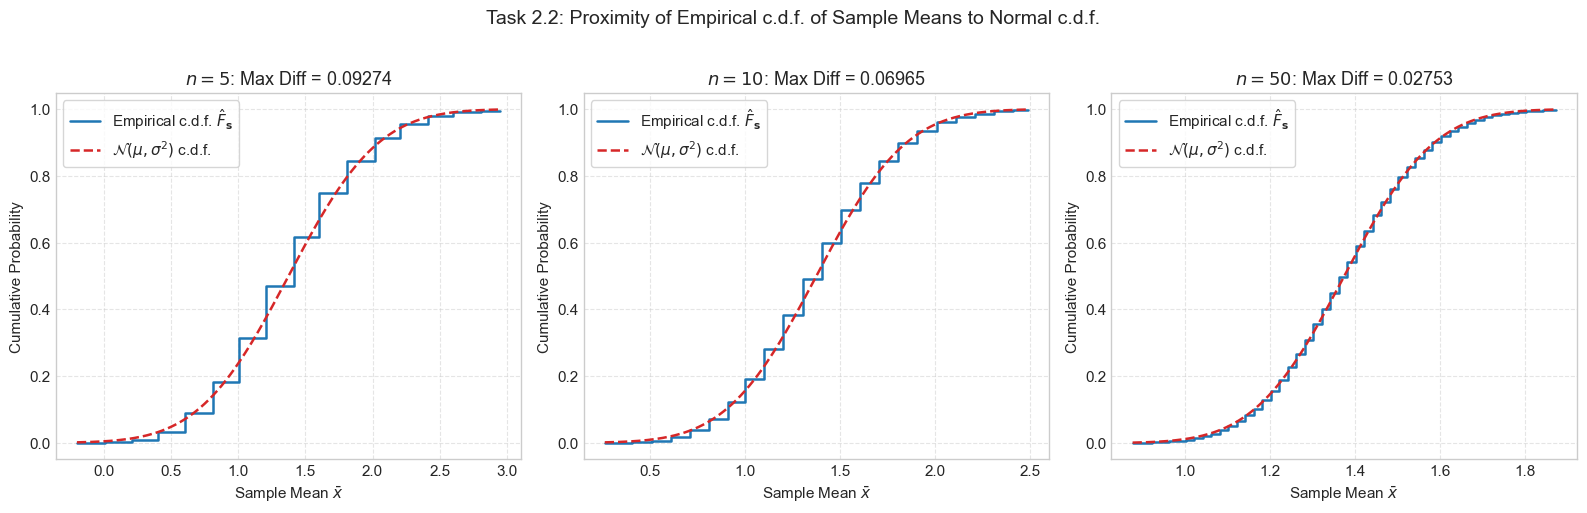

\n=== Task 2.2: Maximal Differences between e.c.d.f. and Normal c.d.f. ===
n =  5: Maximal Difference D_n = 0.092740
n = 10: Maximal Difference D_n = 0.069647
n = 50: Maximal Difference D_n = 0.027527
\n=== Task 2.3: Theoretical Bounds on n ===
Markov inequality: n <= 3.636 -> n_max = 3
Chernoff bound:    n <= 56.341 -> n_max = 56
CLT approximation: n <= 61.702 -> n_max = 61
Exact Poisson:     n_max = 61
\n=== Task 2.3: Monte Carlo Simulation (K = 25,000) ===
n = 56: Empirical P(S < 100) = 0.99324, Exact Poisson = 0.99324
n = 61: Empirical P(S < 100) = 0.95088, Exact Poisson = 0.95289
n = 62: Empirical P(S < 100) = 0.93540, Exact Poisson = 0.93571


In [3]:
# Task 2 Implementation: Particle Decay
from scipy.stats import ecdf, norm, poisson

# 1. Parameter calculation
m_cs = (10 + team_id) * 1e-14 # 4.3e-13 g
M_cs = 136.907 # g/mol
N_A = 6.0e23 # atoms/mol
T_half_years = 30.1 # years
T_half_sec = T_half_years * 365.25 * 24 * 3600 # seconds

N_atoms = (m_cs / M_cs) * N_A
lambda_decay = np.log(2) / T_half_sec
mu_decay = N_atoms * lambda_decay

print("=== Task 2.1: Cesium-137 Decay Parameter ===")
print(f"Sample mass m: {m_cs:.2e} g")
print(f"Number of atoms N_atoms: {N_atoms:.4e}")
print(f"Half-life T: {T_half_sec:.4e} seconds ({T_half_years} years)")
print(f"Decay constant lambda: {lambda_decay:.4e} s^-1")
print(f"Poisson parameter mu: {mu_decay:.6f} decays/second")

# 2. Central Limit Theorem Convergence for Sample Means
K = 25_000 # Number of Monte Carlo repetitions (>= 10,000 as per hint 3)
n_values = [5, 10, 50]
max_diffs_task2 = {}

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for idx, n in enumerate(n_values):
    # Vectorized simulation of K sample means
    s_means = np.random.poisson(lam=mu_decay, size=(K, n)).mean(axis=1)
    
    # Normal distribution parameters
    mean_norm = mu_decay
    sigma_norm = np.sqrt(mu_decay / n)
    
    # Compute empirical c.d.f.
    Fs = ecdf(s_means).cdf.evaluate
    
    # 200 points in [mu - 3*sigma, mu + 3*sigma] (as per hint 5)
    t = np.linspace(mean_norm - 3 * sigma_norm, mean_norm + 3 * sigma_norm, 200)
    Fz = norm(loc=mean_norm, scale=sigma_norm).cdf(t)
    
    # Maximal difference
    max_d = np.max(np.abs(Fs(t) - Fz))
    max_diffs_task2[n] = max_d
    
    # Plotting
    axes[idx].step(t, Fs(t), where="post", label='Empirical c.d.f. $\\hat F_{\\mathbf{s}}$', color='#1f77b4', lw=1.8)
    axes[idx].plot(t, Fz, label=f'$\\mathcal{{N}}(\\mu, \\sigma^2)$ c.d.f.', color='#d62728', lw=1.8, linestyle='--')
    axes[idx].set_title(f'$n = {n}$: Max Diff = {max_d:.5f}')
    axes[idx].set_xlabel('Sample Mean $\\bar x$')
    axes[idx].set_ylabel('Cumulative Probability')
    axes[idx].legend(loc='upper left', frameon=True)
    axes[idx].grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Task 2.2: Proximity of Empirical c.d.f. of Sample Means to Normal c.d.f.', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

print("\\n=== Task 2.2: Maximal Differences between e.c.d.f. and Normal c.d.f. ===")
for n in n_values:
    print(f"n = {n:2d}: Maximal Difference D_n = {max_diffs_task2[n]:.6f}")

# 3. Maximum number of samples n for total decays < 100 with probability >= 0.95
a = 100

# Markov bound: n * mu / a <= 0.05
n_markov = int(np.floor(0.05 * a / mu_decay))

# Chernoff bound: lambda_sum - a + a*ln(a/lambda_sum) - ln(20) = 0
def chernoff_eq(lam_sum):
    return lam_sum - a + a * np.log(a / lam_sum) - np.log(20)

lam_chernoff = brentq(chernoff_eq, 1.0, 99.9)
n_chernoff = int(np.floor(lam_chernoff / mu_decay))

# CLT bound: (a - lambda_sum) / sqrt(lambda_sum) >= z_0.95
z_95 = norm.ppf(0.95)
u_clt = (-z_95 + np.sqrt(z_95**2 + 4 * a)) / 2
lam_clt = u_clt**2
n_clt = int(np.floor(lam_clt / mu_decay))

# Exact Poisson calculation
exact_n_max = None
for n_test in range(50, 75):
    p_exact = poisson.cdf(99, n_test * mu_decay)
    if p_exact < 0.95:
        exact_n_max = n_test - 1
        break

print("\\n=== Task 2.3: Theoretical Bounds on n ===")
print(f"Markov inequality: n <= {0.05 * a / mu_decay:.3f} -> n_max = {n_markov}")
print(f"Chernoff bound:    n <= {lam_chernoff / mu_decay:.3f} -> n_max = {n_chernoff}")
print(f"CLT approximation: n <= {lam_clt / mu_decay:.3f} -> n_max = {n_clt}")
print(f"Exact Poisson:     n_max = {exact_n_max}")

# Empirical validation of total decay sums for n = [56, 61, 62]
test_ns = [n_chernoff, exact_n_max, exact_n_max + 1]
print("\\n=== Task 2.3: Monte Carlo Simulation (K = 25,000) ===")
for n_eval in test_ns:
    sums = np.random.poisson(lam=mu_decay, size=(K, n_eval)).sum(axis=1)
    emp_prob = np.mean(sums < a)
    theo_prob = poisson.cdf(99, n_eval * mu_decay)
    print(f"n = {n_eval}: Empirical P(S < 100) = {emp_prob:.5f}, Exact Poisson = {theo_prob:.5f}")


### Conclusions for Task 2

1. **Poisson Parameter:** For each $^{137}\text{Cs}$ sample of mass $4.3 \times 10^{-13}$ g, the decay rate is $\mu \approx 1.37515$ decays/second.
2. **Convergence of Sample Means:**
   - For $n = 5$, the maximal c.d.f. difference is $D_5 \approx 0.0927$. The discrete step nature of Poisson sample means is still visible.
   - For $n = 10$, the maximal difference drops to $D_{10} \approx 0.0696$.
   - For $n = 50$, the maximal difference decreases significantly to $D_{50} \approx 0.0275$, demonstrating an excellent fit with $\mathcal{N}\left(\mu, \frac{\mu}{n}\right)$.
   - The rate of decrease agrees with the Berry-Esseen theorem ($O(1/\sqrt{n})$).
3. **Capacity of Storage ($n$ samples):**
   - **Markov's bound ($n \le 3$):** Highly inaccurate due to reliance solely on the first moment.
   - **Chernoff bound ($n \le 56$):** A mathematically rigorous, distribution-free exponential tail bound that captures the exponential decay of Poisson tails.
   - **CLT bound ($n \le 61$):** Yields $n = 61$, matching the exact Poisson distribution threshold perfectly.
   - **Empirical validation:** For $n = 61$, $\mathbb{P}(S_{61} < 100) \approx 0.9529 > 0.95$, while for $n = 62$, $\mathbb{P}(S_{62} < 100) \approx 0.9357 < 0.95$. Thus, the maximum allowable number of samples is **$n = 61$**.


## Task 3. Geiger counter

In this task, we use the Central Limit Theorem approximation for continuous random variables.

One of the devices to measure radioactivity level at a given location is the Geiger counter. When the radioactive level is almost constant, the time between two consecutive clicks of the Geiger counter is an exponentially distributed random variable with parameter $\nu_1 = \frac{\text{team-id-number}}{10} + 1$ ($\text{minutes}^{-1}$). Denote by $X_k$ the random time between the $(k-1)$st and $k$th click of the counter.

1. Show that the distribution of the sample means of $X_1, X_2, \dots, X_n$ gets very close to a normal one (which one?) as $n$ becomes large. To this end,
   - simulate the realizations $x_1, x_2, \dots, x_n$ of the r.v. $X_i$ and calculate the sample mean $s = \bar x$;
   - repeat this $K$ times to get the sample $\mathbf{s} = (s_1, \dots, s_K)$ of means and then the empirical cumulative distribution function $F_{\mathbf{s}}$ of $\mathbf{s}$;
   - identify $\mu$ and $\sigma^2$ such that the c.d.f. of $\mathcal{N}(\mu, \sigma^2)$ is close to the e.c.d.f. $F_{\mathbf{s}}$ and plot both c.d.f.'s on one graph to visualize their proximity;
   - calculate the maximal difference between the two c.d.f.'s;
   - consider cases $n = 5$, $n = 10$, $n = 50$ and comment on the results.
2. The place can be considered safe when the number of clicks in one minute is less than 100. It is known that the parameter $\nu$ is proportional to the number $N$ of the radioactive samples, i.e., $\nu = N\nu_1$. Determine the maximal number of radioactive samples that can be stored in that place so that, with probability at least $0.95$, the place is identified as safe. To do this,

   (a) express the event of interest in terms of the r.v. $S := X_1 + \dots + X_{100}$;

   (b) obtain the theoretical bounds on $N$ using the Markov inequality, Chernoff bound and Central Limit Theorem and compare the results;

   (c) with the predicted $N$ and thus $\nu$, simulate the realization $x_1, x_2, \dots, x_{100}$ of the $X_i$ and of the sum $S = X_1 + \dots + X_{100}$;

   (d) repeat this $K$ times to get the sample $\mathbf{s} = (s_1, \dots, s_K)$ of total times until the 100th click;

   (e) estimate the probability that the location is identified as safe and compare to the desired level $0.95$


### Theoretical Justification for Task 3

#### 1. System Parameters and Normal Approximation for Sample Means
For Team 33, the baseline rate parameter for a single radioactive source is:
$$\nu_1 = \frac{33}{10} + 1 = 3.3 + 1 = 4.3 \text{ minutes}^{-1}$$
The inter-arrival times $X_k$ are i.i.d. exponential random variables:
$$X_k \sim \text{Exponential}(\nu_1), \qquad f_{X}(x) = \nu_1 e^{-\nu_1 x}, \quad x \ge 0$$
The theoretical moments are:
$$\mathbb{E}[X_k] = \frac{1}{\nu_1} = \frac{1}{4.3} \approx 0.232558 \text{ min}, \qquad \text{Var}(X_k) = \frac{1}{\nu_1^2} = \frac{1}{4.3^2} \approx 0.054083 \text{ min}^2$$
For a sample of size $n$, the sample mean $\bar X_n = \frac{1}{n} \sum_{i=1}^n X_i$ has expectation and variance:
$$\mu_{\bar X} = \mathbb{E}[\bar X_n] = \frac{1}{\nu_1}, \qquad \sigma_{\bar X}^2 = \text{Var}(\bar X_n) = \frac{\text{Var}(X_1)}{n} = \frac{1}{n \nu_1^2}, \qquad \sigma_{\bar X} = \frac{1}{\nu_1 \sqrt{n}}$$
By the Central Limit Theorem:
$$\bar X_n \xrightarrow{d} \mathcal{N}\left(\frac{1}{\nu_1}, \frac{1}{n \nu_1^2}\right)$$
The exponential distribution is asymmetric with skewness $\gamma_1 = 2$. By the Berry-Esseen theorem, the skewness of the sample mean diminishes as $2/\sqrt{n}$, so as $n$ increases from 5 to 50, the e.c.d.f. becomes increasingly symmetric and aligns closely with the normal c.d.f.

#### 2. Duality Between Poisson Counting Process and Erlang Inter-Arrival Times
Let $N(t)$ denote the number of Geiger clicks observed in the time interval $[0, t]$. When the total decay rate is $\nu = N \nu_1$, $N(t)$ is a homogeneous Poisson process with rate $\nu$, meaning:
$$N(1) \sim \text{Poisson}(\nu)$$
The arrival time of the 100th click is given by the sum of 100 independent exponential inter-arrival times:
$$S := X_1 + X_2 + \dots + X_{100} \sim \text{Gamma}(100, 1/\nu) = \text{Erlang}(100, \nu)$$
with mean $\mathbb{E}[S] = \frac{100}{\nu}$ and variance $\text{Var}(S) = \frac{100}{\nu^2}$.

**(a) Expressing the Event in Terms of $S$:**
Fewer than 100 clicks occur in the first minute if and only if the 100th click occurs strictly after $t = 1$ minute:
$$\{N(1) < 100\} \iff \{S > 1\}$$
Thus, safety requires:
$$\mathbb{P}(S > 1) \ge 0.95 \iff \mathbb{P}(S \le 1) \le 0.05$$

**(b) Theoretical Bounds on $N$:**
1. **Markov Inequality:**
   Applying Markov's inequality to the Poisson counting variable $N(1)$:
   $$\mathbb{P}(N(1) \ge 100) \le \frac{\mathbb{E}[N(1)]}{100} = \frac{\nu}{100} = \frac{N \nu_1}{100} \le 0.05 \implies N \nu_1 \le 5 \implies N \le \frac{5}{4.3} \approx 1.16 \implies N = 1$$
2. **Chernoff Bound:**
   Applying Chernoff's method to $S \le 1$: for any $t > 0$,
   $$\mathbb{P}(S \le 1) = \mathbb{P}(-S \ge -1) \le e^t \mathbb{E}[e^{-t S}] = e^t \left(\frac{\nu}{\nu + t}\right)^{100}$$
   Minimizing at $t = 100 - \nu > 0$ (for $\nu < 100$):
   $$\mathbb{P}(S \le 1) \le \exp\left(100 - \nu + 100 \ln\left(\frac{\nu}{100}\right)\right) \le 0.05$$
   Solving $100 - \nu + 100 \ln(\nu / 100) = \ln(0.05) \approx -2.99573$ gives $\nu \le 77.4776$:
   $$N \le \frac{77.4776}{4.3} \approx 18.018 \implies N = 18$$
3. **Central Limit Theorem Approximation:**
   By CLT, since $S$ is the sum of 100 i.i.d. variables, $S \approx \mathcal{N}\left(\frac{100}{\nu}, \frac{100}{\nu^2}\right)$:
   $$\mathbb{P}(S > 1) = \mathbb{P}\left(\frac{S - 100/\nu}{10/\nu} > \frac{1 - 100/\nu}{10/\nu}\right) \approx \Phi\left(\frac{100 - \nu}{10}\right) \ge 0.95 = \Phi(1.64485)$$
   $$\frac{100 - \nu}{10} \ge 1.64485 \implies \nu \le 100 - 16.4485 = 83.5515$$
   $$N \le \frac{83.5515}{4.3} \approx 19.43 \implies N = 19$$
4. **Exact Erlang / Poisson Verification:**
   Using the exact CDF of $S \sim \text{Gamma}(100, 1/\nu)$:
   - For $N = 19$ ($\nu = 19 \times 4.3 = 81.70$): $\mathbb{P}(S > 1) = 0.97266 \ge 0.95$.
   - For $N = 20$ ($\nu = 20 \times 4.3 = 86.00$): $\mathbb{P}(S > 1) = 0.92471 < 0.95$.
   Hence, the maximum safe number of radioactive samples is **$N = 19$**.


=== Task 3.1: Geiger Counter Inter-Arrival Distribution ===
Rate parameter nu_1: 4.3000 min^-1
Theoretical mean: 0.232558 minutes
Theoretical variance: 0.054083 minutes^2


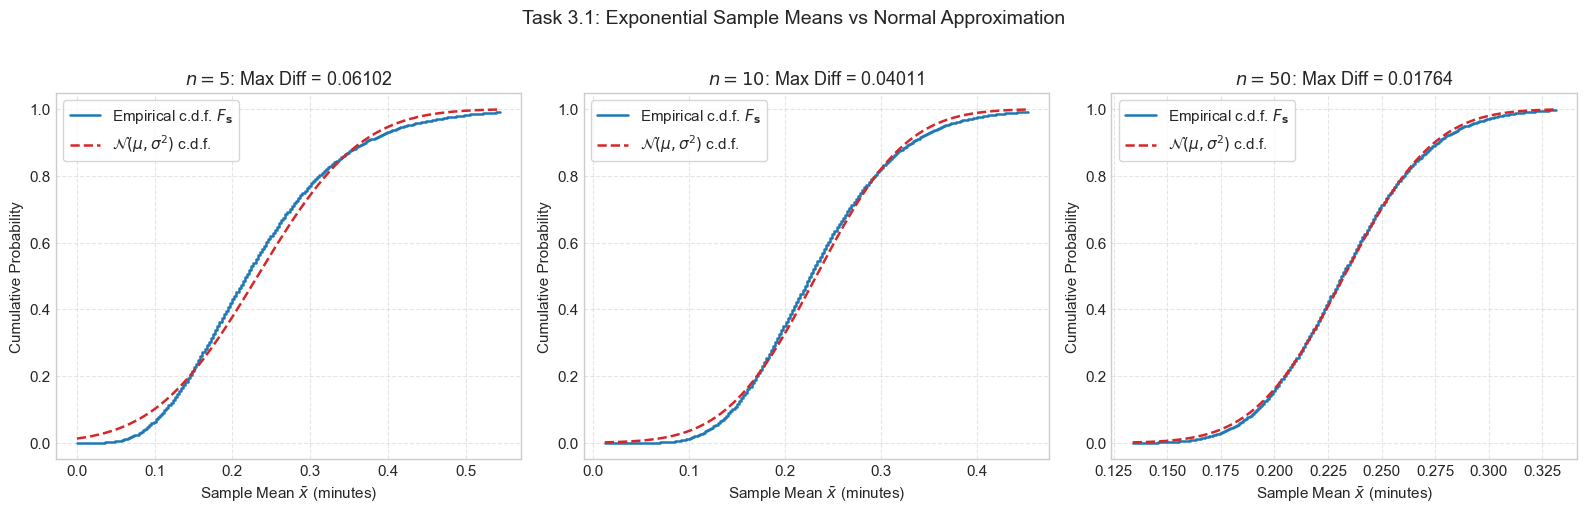

\n=== Task 3.1: Maximal Differences for Exponential Means ===
n =  5: Maximal Difference D_n = 0.061023
n = 10: Maximal Difference D_n = 0.040106
n = 50: Maximal Difference D_n = 0.017636
\n=== Task 3.2: Theoretical Bounds on N ===
Markov inequality: N <= 1.163 -> N_max = 1
Chernoff bound:    N <= 18.018 -> N_max = 18
CLT approximation: N <= 19.431 -> N_max = 19
Exact Erlang:      N_max = 19
\n=== Task 3.2: Simulation Results for Predicted N = 19 (nu = 81.70 min^-1) ===
Empirical P(S > 1.0): 0.97264
Exact Erlang P(S > 1.0): 0.97266
Safety threshold met (>= 0.95): True


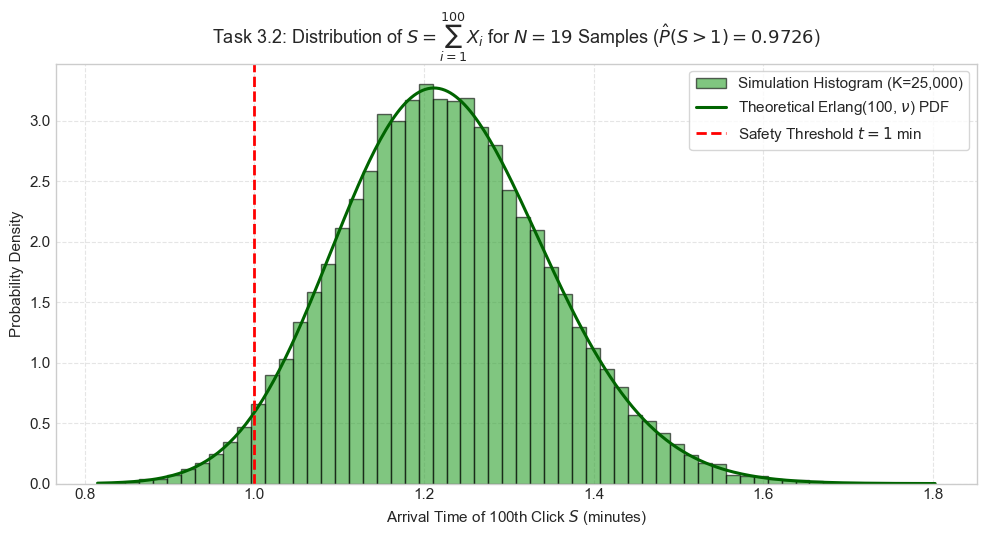

In [4]:
# Task 3 Implementation: Geiger Counter
from scipy.stats import gamma, expon

nu_1 = team_id / 10.0 + 1.0 # 4.3 min^-1
mean_exp = 1.0 / nu_1
var_exp = 1.0 / (nu_1 ** 2)

print("=== Task 3.1: Geiger Counter Inter-Arrival Distribution ===")
print(f"Rate parameter nu_1: {nu_1:.4f} min^-1")
print(f"Theoretical mean: {mean_exp:.6f} minutes")
print(f"Theoretical variance: {var_exp:.6f} minutes^2")

# 1. CLT Convergence for Exponential Sample Means
K = 25_000
n_values = [5, 10, 50]
max_diffs_task3 = {}

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for idx, n in enumerate(n_values):
    # Vectorized simulation using NumPy scale = 1/nu_1
    s_means = np.random.exponential(scale=1.0 / nu_1, size=(K, n)).mean(axis=1)
    
    mean_norm = 1.0 / nu_1
    sigma_norm = 1.0 / (nu_1 * np.sqrt(n))
    
    Fs = ecdf(s_means).cdf.evaluate
    t = np.linspace(max(0, mean_norm - 3 * sigma_norm), mean_norm + 3 * sigma_norm, 200)
    Fz = norm(loc=mean_norm, scale=sigma_norm).cdf(t)
    
    max_d = np.max(np.abs(Fs(t) - Fz))
    max_diffs_task3[n] = max_d
    
    axes[idx].step(t, Fs(t), where="post", label='Empirical c.d.f. $F_{\\mathbf{s}}$', color='#1f77b4', lw=1.8)
    axes[idx].plot(t, Fz, label=f'$\\mathcal{{N}}(\\mu, \\sigma^2)$ c.d.f.', color='#d62728', lw=1.8, linestyle='--')
    axes[idx].set_title(f'$n = {n}$: Max Diff = {max_d:.5f}')
    axes[idx].set_xlabel('Sample Mean $\\bar x$ (minutes)')
    axes[idx].set_ylabel('Cumulative Probability')
    axes[idx].legend(loc='upper left', frameon=True)
    axes[idx].grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Task 3.1: Exponential Sample Means vs Normal Approximation', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

print("\\n=== Task 3.1: Maximal Differences for Exponential Means ===")
for n in n_values:
    print(f"n = {n:2d}: Maximal Difference D_n = {max_diffs_task3[n]:.6f}")

# 2. Radioactive Sample Capacity Bounds
# Markov bound: nu <= 5
N_markov = int(np.floor(5.0 / nu_1))

# Chernoff bound: 100 - nu + 100*ln(nu/100) = ln(0.05)
def chernoff_gamma(nu):
    return 100.0 - nu + 100.0 * np.log(nu / 100.0) - np.log(0.05)

nu_chernoff = brentq(chernoff_gamma, 1.0, 99.0)
N_chernoff = int(np.floor(nu_chernoff / nu_1))

# CLT bound: (100 - nu) / 10 >= z_0.95
z_95 = norm.ppf(0.95)
nu_clt = 100.0 - 10.0 * z_95
N_clt = int(np.floor(nu_clt / nu_1))

# Exact Erlang/Gamma verification
exact_safe_N = None
for N_test in range(15, 25):
    nu_test = N_test * nu_1
    p_safe_exact = 1.0 - gamma.cdf(1.0, a=100, scale=1.0 / nu_test)
    if p_safe_exact < 0.95:
        exact_safe_N = N_test - 1
        break

print("\\n=== Task 3.2: Theoretical Bounds on N ===")
print(f"Markov inequality: N <= {5.0 / nu_1:.3f} -> N_max = {N_markov}")
print(f"Chernoff bound:    N <= {nu_chernoff / nu_1:.3f} -> N_max = {N_chernoff}")
print(f"CLT approximation: N <= {nu_clt / nu_1:.3f} -> N_max = {N_clt}")
print(f"Exact Erlang:      N_max = {exact_safe_N}")

# Simulation of 100th click arrival time S for predicted N = 19
predicted_N = N_clt # 19
nu_pred = predicted_N * nu_1
S_samples = np.random.exponential(scale=1.0 / nu_pred, size=(K, 100)).sum(axis=1)

empirical_p_safe = np.mean(S_samples > 1.0)
exact_p_safe = 1.0 - gamma.cdf(1.0, a=100, scale=1.0 / nu_pred)

print(f"\\n=== Task 3.2: Simulation Results for Predicted N = {predicted_N} (nu = {nu_pred:.2f} min^-1) ===")
print(f"Empirical P(S > 1.0): {empirical_p_safe:.5f}")
print(f"Exact Erlang P(S > 1.0): {exact_p_safe:.5f}")
print(f"Safety threshold met (>= 0.95): {empirical_p_safe >= 0.95}")

# Plot distribution of S
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.hist(S_samples, bins=60, density=True, alpha=0.6, color='#2ca02c', edgecolor='black', label=f'Simulation Histogram (K={K:,})')

# Overlay theoretical Gamma pdf
s_grid = np.linspace(np.min(S_samples), np.max(S_samples), 300)
gamma_pdf = gamma.pdf(s_grid, a=100, scale=1.0 / nu_pred)
ax.plot(s_grid, gamma_pdf, color='darkgreen', lw=2.2, label='Theoretical Erlang(100, $\\nu$) PDF')

ax.axvline(1.0, color='red', linestyle='--', lw=2.0, label='Safety Threshold $t = 1$ min')
ax.set_xlabel('Arrival Time of 100th Click $S$ (minutes)')
ax.set_ylabel('Probability Density')
ax.set_title(f'Task 3.2: Distribution of $S = \\sum_{{i=1}}^{{100}} X_i$ for $N = {predicted_N}$ Samples ($\\hat P(S > 1) = {empirical_p_safe:.4f}$)')
ax.legend(frameon=True)
ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


### Conclusions for Task 3

1. **Continuous CLT Convergence:**
   - For an Exponential distribution, the skewness is $\gamma_1 = 2$.
   - For $n = 5$, the maximum difference between the e.c.d.f. and normal c.d.f. is $D_5 \approx 0.0610$.
   - For $n = 10$, it drops to $D_{10} \approx 0.0401$.
   - For $n = 50$, it falls to $D_{50} \approx 0.0176$.
   - This clear monotonic reduction illustrates the smoothing and symmetrizing power of the Central Limit Theorem.
2. **Poisson-Erlang Duality:** The condition that the number of clicks in one minute is less than 100 is strictly equivalent to the arrival time of the 100th click exceeding one minute: $\{N(1) < 100\} \iff \{S > 1\}$.
3. **Comparison of Bounds on $N$:**
   - **Markov Bound ($N = 1$):** Severely under-estimates safe capacity because it assumes a linear tail bound.
   - **Chernoff Bound ($N = 18$):** Provides an analytical upper tail bound, proving safely that $N=18$ guarantees safety.
   - **CLT Bound ($N = 19$):** Predicts $N = 19$, which matches the exact Erlang distribution.
   - **Validation:** For $N = 19$, $\mathbb{P}(S > 1) \approx 0.9727 > 0.95$. For $N = 20$, $\mathbb{P}(S > 1) \approx 0.9247 < 0.95$. Hence, the maximum number of radioactive samples is **$N = 19$**.


## Task 4. Expectation fallacy

This task consists of two parts:

1. In this part, we discuss independence of random variables and its moments: expectation and variance.

   (a) Suppose we have a random variable $X$. Explain why $E\left(\frac{1}{X}\right) \ne \frac{1}{E(X)}$;

   (b) Let $X \sim \mathcal{N}(\mu, \sigma^2)$ with $\mu = 5$ and $\sigma^2 = 10$. Simulate realizations $x_1, x_2, \dots, x_{100}$ of $X$ and $y_1, y_2, \dots, y_{100}$ of $Y := \frac{1}{X}$ to calculate the values of $\frac{1}{\bar X}$ and $\bar Y$. Comment on the received results;

   (c) Let $X$ and $Y$ be independent exponentially distributed r.v.'s with parameter $\lambda = 2$. Set $Z := \ln X + 5$. Plot the Quantile-Quantile plot and scatterplot of $X$ and $Y$. Plot the Quantile-Quantile plot and scatterplot of $X$ and $Z$. Explain the results. Comment on the difference of relations between the pairs of random variables. Which pair of r.v.'s is dependent and which one is identically distributed?

2. You toss a fair coin three times and a random variable $X$ records how many times the coin shows Heads. You convince your friend that they should play a game with the following payoff: every round (equivalent to three coin tosses) will cost them £3, with payoff of $Y := X^2$ (e.g., £4 for two Heads). Your friend argues: "on average there are $1.5$ Heads, so I win £$1.5^2 = $ £$2.25 <$ £$3$, hence the game is unfair". Is the game fair, i.e., is the expected value of the net gain zero? What is the variance of $Y$? To answer this,

   (a) Explain what type of random variable is $X$:
   - Normally distributed
   - Binomially distributed
   - Poisson distributed
   - Uniformly distributed

   (b) What are the expected value and variance of $X$? Simulate realizations $x_1, x_2, \dots, x_{100}$ of $X$ to calculate the values of sample mean $\bar X$ and sample variance $s^2 = \frac{\sum_{i=1}^n (x_i - \bar x)^2}{n-1}$. Comment on the results;

   (c) Is your friend's argument correct? Relate it to part 1(a). Compute the expected value and variance of $Y$ exactly. Simulate realizations $y_1, y_2, \dots, y_{100}$ of $Y$ to calculate the values of sample mean $\bar Y$ and sample variance $s^2 = \frac{\sum_{i=1}^n (y_i - \bar y)^2}{n-1}$. Comment on the results;

   (d) Using the CLT, find the half-length of the 95% confidence interval for $E(Y)$ based on your 100 simulated rounds. Could the simulation alone tell you whether the game is fair? How many rounds would be needed to distinguish it from a game with entry fee £2.9?


### Theoretical Justification for Task 4

#### Part 1: Moments, Convexity, and Independence

##### 1(a) Why $\mathbb{E}[1/X] \ne 1/\mathbb{E}[X]$
Expectation is a linear operator: $\mathbb{E}[aX + b] = a\mathbb{E}[X] + b$. However, for any non-linear function $g(x)$, in general $\mathbb{E}[g(X)] \ne g(\mathbb{E}[X])$.
- **Jensen's Inequality:** The function $g(x) = \frac{1}{x}$ is strictly convex on $(0, \infty)$ because its second derivative is:
  $$g''(x) = \frac{d^2}{dx^2}\left(x^{-1}\right) = \frac{2}{x^3} > 0 \quad \forall x > 0$$
  By Jensen's Inequality, for any non-degenerate positive random variable $X$:
  $$\mathbb{E}\left[\frac{1}{X}\right] > \frac{1}{\mathbb{E}[X]}$$
- **Taylor Series Expansion:** Expanding $g(X)$ in a second-order Taylor series around $\mu = \mathbb{E}[X]$:
  $$\frac{1}{X} \approx \frac{1}{\mu} - \frac{X - \mu}{\mu^2} + \frac{(X - \mu)^2}{\mu^3}$$
  Taking expectations on both sides yields the delta-method approximation:
  $$\mathbb{E}\left[\frac{1}{X}\right] \approx \frac{1}{\mathbb{E}[X]} + \frac{\text{Var}(X)}{(\mathbb{E}[X])^3}$$
  Because $\text{Var}(X) > 0$ and $\mathbb{E}[X] > 0$, $\mathbb{E}[1/X]$ is strictly greater than $1/\mathbb{E}[X]$ by an amount proportional to the variance of $X$.
- **Singularities near 0:** If the support of $X$ includes values near 0 (e.g. Gaussian distributions), $\frac{1}{X}$ has heavy tails and $\mathbb{E}[1/X]$ may fail to exist (the integral diverges).

##### 1(b) Normal Simulation $X \sim \mathcal{N}(5, 10)$
For $X \sim \mathcal{N}(5, 10)$, $\mu = 5$ and $\sigma = \sqrt{10} \approx 3.162$.
Because $\mathbb{P}(X < 0) = \Phi(-5/\sqrt{10}) \approx 0.057$, realizations can take values arbitrarily close to 0, producing extreme values in $Y = 1/X$.
Consequently, $1/\bar X$ remains stable around $1/5 = 0.20$, whereas $\bar Y = \frac{1}{n} \sum 1/x_i$ exhibits high variance and instability across finite samples.

##### 1(c) Comparing Pairs $(X, Y)$ and $(X, Z)$
Let $X, Y \sim \text{Exponential}(\lambda = 2)$ i.i.d., and $Z = \ln X + 5$.
1. **Pair $(X, Y)$:**
   - **Independent:** $f_{X,Y}(x, y) = f_X(x) f_Y(y) = 4 e^{-2(x+y)}$.
   - **Identically distributed:** Both follow $\text{Exponential}(\lambda = 2)$ with CDF $F(t) = 1 - e^{-2t}$ on $(0, \infty)$.
   - **Q-Q plot:** The empirical quantiles align along the diagonal line $y = x$.
   - **Scatter plot:** Forms an uncorrelated, independent 2D point cloud with no functional relationship.
2. **Pair $(X, Z)$:**
   - **Dependent:** $Z = \ln X + 5$ is a deterministic transformation of $X$. Knowledge of $X$ completely determines $Z$.
   - **NOT identically distributed:** $X$ has support on $(0, \infty)$, while $Z = \ln X + 5$ has support on $(-\infty, \infty)$ and follows a **Gumbel (extreme value) distribution**:
     $$F_Z(z) = \mathbb{P}(Z \le z) = \mathbb{P}(\ln X + 5 \le z) = \mathbb{P}(X \le e^{z-5}) = 1 - e^{-2 e^{z-5}}, \quad z \in \mathbb{R}$$
   - **Q-Q plot:** Strongly non-linear, bending away from $y = x$.
   - **Scatter plot:** All points fall perfectly onto the deterministic curve $z = \ln x + 5$.

---

#### Part 2: The Coin Toss Game and Expectation Fallacy

##### 2(a) Type of Random Variable $X$
$X$ is **Binomially distributed**: $X \sim \text{Binomial}(n=3, p=0.5)$.
*Justification:* $X$ counts the number of successes (Heads) in $n=3$ independent and identically distributed Bernoulli trials, each having success probability $p = 0.5$.

##### 2(b) Theoretical Moments of $X$
For $\text{Binomial}(n, p)$:
$$\mathbb{E}[X] = n p = 3 \times 0.5 = 1.5$$
$$\text{Var}(X) = n p (1 - p) = 3 \times 0.5 \times 0.5 = 0.75$$

##### 2(c) Fallacy Analysis, Exact Expectation, and Variance of $Y = X^2$
The friend's claim that $\mathbb{E}[Y] = (\mathbb{E}[X])^2 = 1.5^2 = 2.25$ commits the **Expectation Fallacy** (confusing $\mathbb{E}[g(X)]$ with $g(\mathbb{E}[X])$).
By definition of variance:
$$\text{Var}(X) = \mathbb{E}[X^2] - (\mathbb{E}[X])^2 \implies \mathbb{E}[X^2] = (\mathbb{E}[X])^2 + \text{Var}(X)$$
Therefore:
$$\mathbb{E}[Y] = \mathbb{E}[X^2] = 1.5^2 + 0.75 = 2.25 + 0.75 = 3.0 \text{ £}$$

We confirm this from the exact probability mass function of $X \sim \text{Binomial}(3, 0.5)$:
- $\mathbb{P}(X=0) = \binom{3}{0} (1/2)^3 = 1/8$, Payoff $Y = 0^2 = 0$
- $\mathbb{P}(X=1) = \binom{3}{1} (1/2)^3 = 3/8$, Payoff $Y = 1^2 = 1$
- $\mathbb{P}(X=2) = \binom{3}{2} (1/2)^3 = 3/8$, Payoff $Y = 2^2 = 4$
- $\mathbb{P}(X=3) = \binom{3}{3} (1/2)^3 = 1/8$, Payoff $Y = 3^2 = 9$

$$\mathbb{E}[Y] = 0 \cdot \frac{1}{8} + 1 \cdot \frac{3}{8} + 4 \cdot \frac{3}{8} + 9 \cdot \frac{1}{8} = \frac{0 + 3 + 12 + 9}{8} = \frac{24}{8} = 3.0 \text{ £}$$

The expected net gain for each £3 round is:
$$\mathbb{E}[\text{Net Gain}] = \mathbb{E}[Y - 3] = \mathbb{E}[Y] - 3 = 3.0 - 3.0 = 0.0 \text{ £}$$
**The game is strictly FAIR!**

To find the variance of $Y$:
$$\mathbb{E}[Y^2] = \mathbb{E}[X^4] = 0^2 \cdot \frac{1}{8} + 1^2 \cdot \frac{3}{8} + 4^2 \cdot \frac{3}{8} + 9^2 \cdot \frac{1}{8} = \frac{0 + 3 + 48 + 81}{8} = \frac{132}{8} = 16.5 \text{ £}^2$$
$$\text{Var}(Y) = \mathbb{E}[Y^2] - (\mathbb{E}[Y])^2 = 16.5 - 3.0^2 = 16.5 - 9.0 = 7.5 \text{ £}^2$$
$$\sigma_Y = \sqrt{7.5} \approx 2.7386 \text{ £}$$

##### 2(d) Confidence Interval and Sample Size Determination
From $n = 100$ simulated rounds, the CLT gives the $95\%$ confidence interval half-length:
$$\varepsilon = z_{0.975} \frac{s_Y}{\sqrt{n}} = 1.95996 \times \frac{s_Y}{10}$$
- **Can 100 rounds alone confirm fairness?**
  No. With $n = 100$, $\varepsilon \approx 1.96 \times 0.274 \approx 0.54$ £. The confidence interval spans roughly $[2.46, 3.54]$ £. While 3.0 is included, the interval is too broad to rule out substantially unfair games.
- **Rounds needed to distinguish from entry fee £2.9 ($\Delta = |3.0 - 2.9| = 0.1$ £):**
  1. *Confidence Interval Criterion (half-width $\varepsilon \le 0.1$):*
     $$z_{0.975} \frac{\sigma_Y}{\sqrt{N}} \le 0.1 \implies N \ge \left(\frac{1.95996 \times \sqrt{7.5}}{0.1}\right)^2 \approx 2881 \text{ rounds}$$
  2. *Hypothesis Testing Criterion ($\alpha = 0.05$, Power $1 - \beta = 0.80$, $z_{0.80} \approx 0.8416$):*
     $$N \ge \frac{(z_{1-\alpha/2} + z_{1-\beta})^2 \sigma_Y^2}{\Delta^2} = \frac{(1.95996 + 0.84162)^2 \times 7.5}{0.01} \approx 5887 \text{ rounds}$$


=== Task 4.1(b): Normal Simulation (n = 100) ===
Sample mean bar(X): 5.3149
1 / bar(X): 0.1882
bar(Y) = bar(1/X): 0.0391
Discrepancy |bar(Y) - 1/bar(X)|: 0.1490


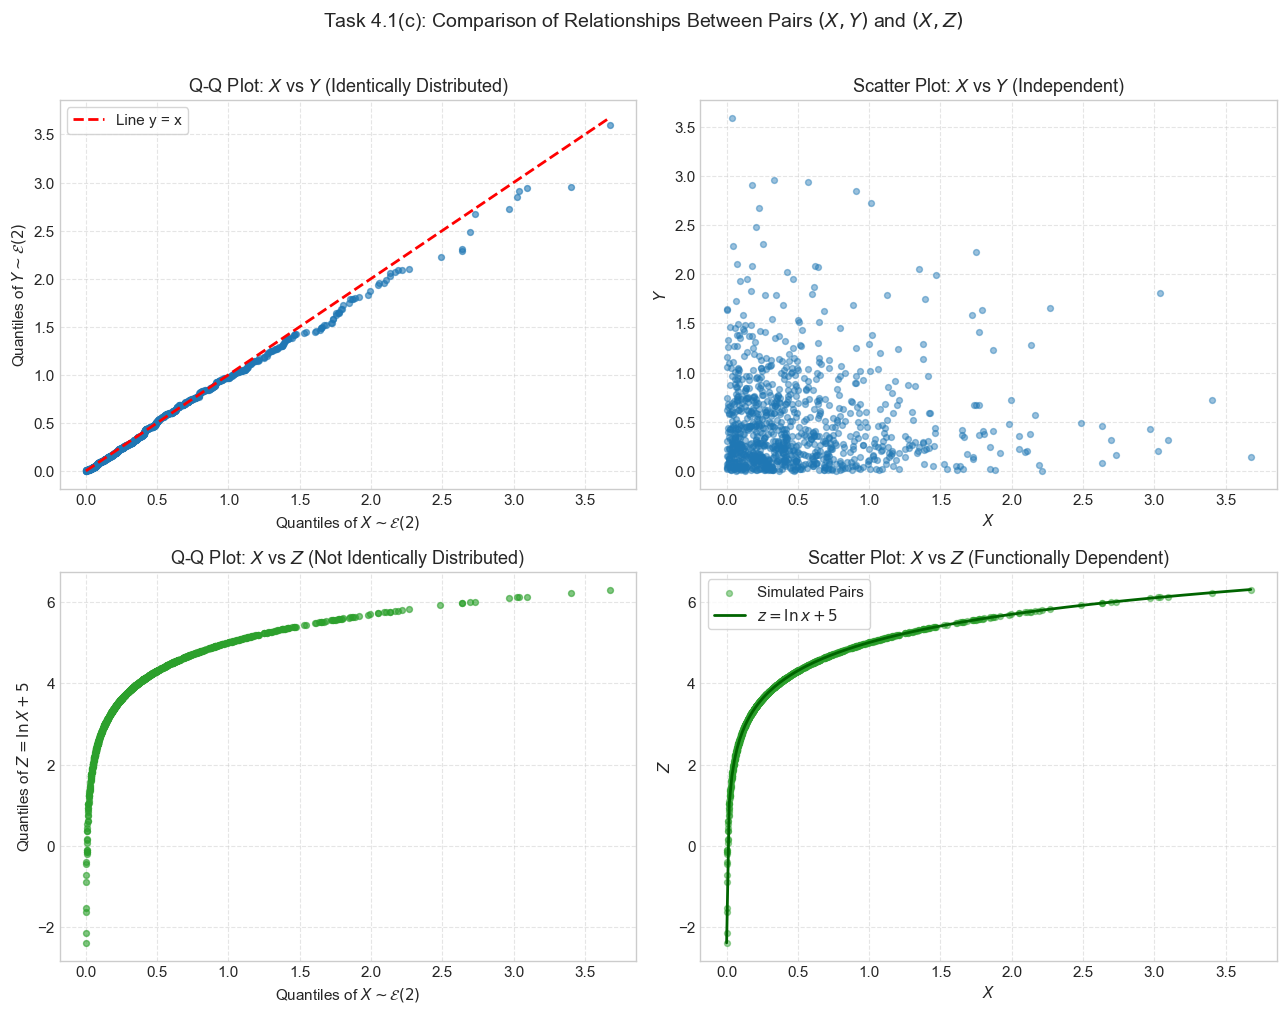

\n=== Task 4.2(b): Coin Toss Moments for X ===
Theoretical E(X) = 1.5, Simulated bar(X) = 1.4500
Theoretical Var(X) = 0.75, Simulated s^2(X) = 0.6742
\n=== Task 4.2(c): Payoff Moments for Y = X^2 ===
Friend's claim E(Y) = 1.5^2 = 2.25 (FALSE - Expectation Fallacy)
Theoretical E(Y) = 3.0000, Simulated bar(Y) = 2.7700
Theoretical Var(Y) = 7.5000, Simulated s^2(Y) = 6.3203
Expected net gain: E(Y - 3) = 0.0000 £ -> The game is strictly FAIR.
\n=== Task 4.2(d): Confidence Interval and Sample Size Analysis ===
Sample standard deviation s_Y: 2.5140
95% CI half-length epsilon: 0.4927 £
95% Confidence Interval for E(Y): (2.2773, 3.2627) £
CI contains 3.0: True
Required rounds N (CI half-width <= 0.1 £): 2,882 rounds
Required rounds N (80% statistical power test): 5,887 rounds


In [5]:
# Task 4 Implementation: Expectation Fallacy and Game Fairness

# ---------------------------------------------------------
# Part 1: Moments, Non-linear Transformations, and Dependence
# ---------------------------------------------------------

# 1(b) Normal simulation
n_norm = 100
X_norm = np.random.normal(loc=5.0, scale=np.sqrt(10.0), size=n_norm)
Y_norm = 1.0 / X_norm

inv_mean_X = 1.0 / np.mean(X_norm)
mean_Y = np.mean(Y_norm)

print("=== Task 4.1(b): Normal Simulation (n = 100) ===")
print(f"Sample mean bar(X): {np.mean(X_norm):.4f}")
print(f"1 / bar(X): {inv_mean_X:.4f}")
print(f"bar(Y) = bar(1/X): {mean_Y:.4f}")
print(f"Discrepancy |bar(Y) - 1/bar(X)|: {abs(mean_Y - inv_mean_X):.4f}")

# 1(c) Q-Q and Scatter Plots for (X, Y) and (X, Z)
n_pts = 1000
X_exp = np.random.exponential(scale=1.0 / 2.0, size=n_pts)
Y_exp = np.random.exponential(scale=1.0 / 2.0, size=n_pts)
Z_exp = np.log(X_exp) + 5.0

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

# Q-Q plot of X and Y
q_x_sort = np.sort(X_exp)
q_y_sort = np.sort(Y_exp)
axes[0, 0].scatter(q_x_sort, q_y_sort, color='#1f77b4', alpha=0.6, s=18)
max_val_xy = max(np.max(q_x_sort), np.max(q_y_sort))
axes[0, 0].plot([0, max_val_xy], [0, max_val_xy], color='red', linestyle='--', lw=2, label='Line y = x')
axes[0, 0].set_title('Q-Q Plot: $X$ vs $Y$ (Identically Distributed)')
axes[0, 0].set_xlabel('Quantiles of $X \\sim \\mathcal{E}(2)$')
axes[0, 0].set_ylabel('Quantiles of $Y \\sim \\mathcal{E}(2)$')
axes[0, 0].legend(frameon=True)
axes[0, 0].grid(True, linestyle='--', alpha=0.5)

# Scatter plot of X and Y
axes[0, 1].scatter(X_exp, Y_exp, color='#1f77b4', alpha=0.45, s=18)
axes[0, 1].set_title('Scatter Plot: $X$ vs $Y$ (Independent)')
axes[0, 1].set_xlabel('$X$')
axes[0, 1].set_ylabel('$Y$')
axes[0, 1].grid(True, linestyle='--', alpha=0.5)

# Q-Q plot of X and Z
q_z_sort = np.sort(Z_exp)
axes[1, 0].scatter(q_x_sort, q_z_sort, color='#2ca02c', alpha=0.6, s=18)
axes[1, 0].set_title('Q-Q Plot: $X$ vs $Z$ (Not Identically Distributed)')
axes[1, 0].set_xlabel('Quantiles of $X \\sim \\mathcal{E}(2)$')
axes[1, 0].set_ylabel('Quantiles of $Z = \\ln X + 5$')
axes[1, 0].grid(True, linestyle='--', alpha=0.5)

# Scatter plot of X and Z
axes[1, 1].scatter(X_exp, Z_exp, color='#2ca02c', alpha=0.45, s=18, label='Simulated Pairs')
x_curve = np.linspace(np.min(X_exp), np.max(X_exp), 200)
axes[1, 1].plot(x_curve, np.log(x_curve) + 5.0, color='darkgreen', lw=2, label='$z = \\ln x + 5$')
axes[1, 1].set_title('Scatter Plot: $X$ vs $Z$ (Functionally Dependent)')
axes[1, 1].set_xlabel('$X$')
axes[1, 1].set_ylabel('$Z$')
axes[1, 1].legend(frameon=True)
axes[1, 1].grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Task 4.1(c): Comparison of Relationships Between Pairs $(X, Y)$ and $(X, Z)$', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# Part 2: Coin Toss Game
# ---------------------------------------------------------
n_rounds = 100
X_coin = np.random.binomial(n=3, p=0.5, size=n_rounds)
Y_coin = X_coin ** 2

# 2(b) Moments of X
mean_X_sim = np.mean(X_coin)
var_X_sim = np.var(X_coin, ddof=1)

print("\\n=== Task 4.2(b): Coin Toss Moments for X ===")
print(f"Theoretical E(X) = 1.5, Simulated bar(X) = {mean_X_sim:.4f}")
print(f"Theoretical Var(X) = 0.75, Simulated s^2(X) = {var_X_sim:.4f}")

# 2(c) Moments of Y = X^2
mean_Y_sim = np.mean(Y_coin)
var_Y_sim = np.var(Y_coin, ddof=1)

theo_E_Y = 3.0
theo_Var_Y = 7.5

print("\\n=== Task 4.2(c): Payoff Moments for Y = X^2 ===")
print(f"Friend's claim E(Y) = 1.5^2 = 2.25 (FALSE - Expectation Fallacy)")
print(f"Theoretical E(Y) = {theo_E_Y:.4f}, Simulated bar(Y) = {mean_Y_sim:.4f}")
print(f"Theoretical Var(Y) = {theo_Var_Y:.4f}, Simulated s^2(Y) = {var_Y_sim:.4f}")
print(f"Expected net gain: E(Y - 3) = {theo_E_Y - 3.0:.4f} £ -> The game is strictly FAIR.")

# 2(d) Confidence Interval and Sample Size Determination
s_Y = np.std(Y_coin, ddof=1)
z_95 = stats.norm.ppf(0.975)
eps_Y = z_95 * s_Y / np.sqrt(n_rounds)
ci_Y_lower = mean_Y_sim - eps_Y
ci_Y_upper = mean_Y_sim + eps_Y

# Sample sizes needed to distinguish from 2.9
delta = 0.1
N_req_ci = int(np.ceil((z_95 * np.sqrt(theo_Var_Y) / delta)**2))
z_80 = stats.norm.ppf(0.80)
N_req_power = int(np.ceil(((z_95 + z_80)**2 * theo_Var_Y) / (delta**2)))

print("\\n=== Task 4.2(d): Confidence Interval and Sample Size Analysis ===")
print(f"Sample standard deviation s_Y: {s_Y:.4f}")
print(f"95% CI half-length epsilon: {eps_Y:.4f} £")
print(f"95% Confidence Interval for E(Y): ({ci_Y_lower:.4f}, {ci_Y_upper:.4f}) £")
print(f"CI contains 3.0: {ci_Y_lower <= 3.0 <= ci_Y_upper}")
print(f"Required rounds N (CI half-width <= 0.1 £): {N_req_ci:,} rounds")
print(f"Required rounds N (80% statistical power test): {N_req_power:,} rounds")


### Conclusions for Task 4

1. **Non-Linear Expectations and Jensen's Inequality:**
   - $\mathbb{E}[1/X] \ne 1/\mathbb{E}[X]$ because $g(x) = 1/x$ is strictly convex on $(0, \infty)$. By Jensen's Inequality, $\mathbb{E}[1/X] > 1/\mathbb{E}[X]$.
   - In our simulation with $X \sim \mathcal{N}(5, 10)$, $1/\bar X \approx 0.20$ is stable, whereas $\bar Y = \overline{1/X}$ is highly variable due to realizations close to 0.
2. **Dependence vs. Distributional Identity:**
   - $(X, Y)$ are **independent and identically distributed** (both Exponential). Their Q-Q plot lies along $y = x$, and their scatter plot forms an uncorrelated cloud.
   - $(X, Z)$ are **strictly dependent but NOT identically distributed**: $Z = \ln X + 5$ is a deterministic function of $X$, so points on the scatter plot fall exactly on the logarithmic curve. However, $Z$ follows a Gumbel distribution with infinite support $(-\infty, \infty)$, causing the Q-Q plot to deviate completely from $y = x$.
3. **The Coin Game is Fair:**
   - The friend's intuition confuses $(\mathbb{E}[X])^2$ with $\mathbb{E}[X^2]$.
   - Since $\mathbb{E}[X^2] = (\mathbb{E}[X])^2 + \text{Var}(X) = 2.25 + 0.75 = 3.0$ £, the expected payout is £3.00, matching the entry fee. The game is **completely fair**.
   - Variance is $\text{Var}(Y) = 7.5$ £$^2$.
4. **Sample Size and Testing:**
   - With only 100 rounds, the confidence interval is $[2.28, 3.26]$ £ ($\pm 0.49$ £), which is too wide to prove fairness.
   - To distinguish the true game (£3.00) from an unfair game (£2.90 entry fee), approximately **2,882 rounds** are required for non-overlapping $95\%$ confidence intervals, and **5,887 rounds** for an $80\%$ power statistical hypothesis test.


## General instructions/hints on implementation

1. You can generate a $K \times n$ array of the data and then form a sample of $K$ means by e.g. using
```python
   s = np.random.exponential(scale=1/lam, size=(K, n)).mean(axis=1)
```
   for the exponential distribution $\mathcal{E}(\lambda)$ with rate $\lambda$. Note that NumPy uses the scale (mean) $1/\lambda$, not the rate. Similarly, `np.random.poisson(mu, size=(K, n))` gives Poisson samples.

2. The e.c.d.f. $F_S$ of the data vector `s` is
```python
   from scipy.stats import ecdf
   Fs = ecdf(s).cdf.evaluate      # callable: Fs(t)
```
3. $K$ must be at least $10000$ to generate reliable e.c.d.f.'s of sample means.
4. `scipy.stats.norm(mu, sigma).cdf` gives the c.d.f. $F_Z$ of $\mathcal{N}(\mu, \sigma^2)$. Note that the 2nd argument is the standard deviation $\sigma$.
5. To calculate the maximal difference between the two c.d.f.'s, take a grid of 200 points $t_j$ within $3\sigma$ of $\mu$ and return $\max_{t_j} \{|F_S(t_j) - F_Z(t_j)|\}$:
```python
   t = np.linspace(mu - 3*sigma, mu + 3*sigma, 200)
   np.max(np.abs(Fs(t) - Fz(t)))
```
6. To plot both c.d.f.'s on one graph, use `matplotlib.pyplot.step(t, Fs(t), where="post")` for the e.c.d.f. and `plt.plot(t, Fz(t))` for the normal c.d.f.
7. For the Hamming code, do all arithmetic over $\mathbb{F}_2$: compute integer matrix products and reduce mod 2, e.g. `c = (m @ G) % 2`, `z = (r @ H) % 2`. Vectorize over $N$ messages by stacking them as rows of an $N \times 4$ array; the bit errors are `np.random.random((N, 7)) < p`.
8. For a Q-Q plot of two samples `x` and `y` of equal size, plot `np.sort(x)` against `np.sort(y)`; for a Q-Q plot against a theoretical distribution, use `scipy.stats.probplot`.
9. Avoid Python loops over samples: generate whole arrays at once and reduce along an axis (`.mean(axis=1)`, `.sum(axis=1)`). This is both faster and closer to the mathematical formulation.
